In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay
from sklearn.preprocessing import normalize , LabelEncoder
from sklearn.model_selection import train_test_split, KFold
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense, Dropout, Activation, Input
from tensorflow.keras.models import Model, Sequential
from keras.regularizers import l2
from keras.callbacks import EarlyStopping
import xgboost as xgb
from functions import *

In [2]:
kf = KFold(n_splits=5, shuffle=True, random_state=111)

In [3]:
# data read and types check
df = pd.read_csv('https://raw.githubusercontent.com/paq88/Deep-Learning-in-classification-of-common-Carp-intestine-classification/refs/heads/main/Data/Gut_bacteria_merged.csv')
print(df.shape)
print(df.dtypes)
df.head()

(124, 127)
pond                                                                                           object
d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae             float64
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae       float64
d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae                    float64
d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae                    float64
                                                                                               ...   
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae           float64
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae      float64
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae           float64
d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales

,pond,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
0,Gut_S10,2319.0,2187.0,1743.0,500.0,521.0,286.0,366.0,612.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Gut_S10,3391.0,2071.0,355.0,1054.0,1024.0,1952.0,66.0,217.0,95.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Gut_S10,1338.0,7053.0,669.0,279.0,329.0,63.0,52.0,1338.0,139.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Gut_S10,1582.0,15595.0,124.0,503.0,309.0,5.0,3418.0,326.0,76.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Gut_S10,1463.0,3891.0,541.0,7.0,13.0,11.0,61.0,398.0,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df = df.fillna(0)
df.head()

,pond,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
0,Gut_S10,2319.0,2187.0,1743.0,500.0,521.0,286.0,366.0,612.0,160.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Gut_S10,3391.0,2071.0,355.0,1054.0,1024.0,1952.0,66.0,217.0,95.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Gut_S10,1338.0,7053.0,669.0,279.0,329.0,63.0,52.0,1338.0,139.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Gut_S10,1582.0,15595.0,124.0,503.0,309.0,5.0,3418.0,326.0,76.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Gut_S10,1463.0,3891.0,541.0,7.0,13.0,11.0,61.0,398.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
print(df.shape)
df.describe()

(124, 127)


,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
count,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,...,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000
mean,831.653226,8693.169355,171.370968,71.137097,105.548387,196.209677,677.419355,375.854839,53.169355,25.241935,...,0.096774,0.298387,0.080645,2.153226,0.217742,1.604839,0.153226,0.096774,0.266129,0.185484
std,1120.105607,5604.123141,224.484829,146.755443,192.490201,637.902078,2845.964849,456.780652,98.483354,67.552253,...,1.077632,2.270274,0.898027,20.938565,2.093585,13.805159,1.706250,1.077632,2.537872,2.065461
min,0.000000,167.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,106.750000,3913.500000,37.750000,0.000000,0.000000,6.750000,0.000000,55.500000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,469.500000,7454.500000,105.500000,2.000000,13.500000,27.500000,0.000000,211.000000,4.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1037.750000,12774.000000,241.000000,91.500000,131.000000,118.250000,48.750000,467.250000,62.250000,15.250000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,6597.000000,26160.000000,1743.000000,1054.000000,1024.000000,5020.000000,23193.000000,2505.000000,581.000000,539.000000,...,12.000000,23.000000,10.000000,232.000000,23.000000,144.000000,19.000000,12.000000,28.000000,23.000000


In [6]:
predictors = df.columns[1:]
print(len(predictors))

126


## CLR transformation

In [7]:
df[predictors] = pd.DataFrame(clr_manual(df[predictors]),columns = df[predictors].columns)

In [8]:
predictors


Index(['d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae',
       'd__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae',
       'd__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__',
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae',
       'd__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae',
       'd__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae',
       'd__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae',
       ...
       'd__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alterom

In [9]:
df.describe()

,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelotrichaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Aeromonadales;f__Aeromonadaceae,d__Bacteria;p__Firmicutes;c__Clostridia;o__Clostridiales;f__Clostridiaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Lactobacillales;f__Enterococcaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Yersiniaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;__;__,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales;f__Enterobacteriaceae,d__Bacteria;p__Fusobacteriota;c__Fusobacteriia;o__Fusobacteriales;f__Fusobacteriaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Dysgonomonadaceae,d__Bacteria;p__Firmicutes;c__Bacilli;o__Erysipelotrichales;f__Erysipelatoclostridiaceae,...,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Alteromonadales;f__Alteromonadaceae,d__Bacteria;p__Acidobacteriota;c__Vicinamibacteria;o__Vicinamibacterales;f__uncultured,d__Bacteria;p__Verrucomicrobiota;c__Verrucomicrobiae;o__Pedosphaerales;f__Pedosphaeraceae,d__Bacteria;p__Firmicutes;c__Negativicutes;o__Veillonellales-Selenomonadales;f__Sporomusaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Alcaligenaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Vibrionales;f__Vibrionaceae,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Moraxellaceae,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Crocinitomicaceae,d__Bacteria;p__Campilobacterota;c__Campylobacteria;o__Campylobacterales;f__Arcobacteraceae,d__Bacteria;p__Actinobacteriota;c__Actinobacteria;o__Actinomycetales;f__Actinomycetaceae
count,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,...,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000,124.000000
mean,5.184129,8.149255,3.644067,1.438091,1.940012,2.662686,1.427626,4.205627,1.532341,0.765683,...,-0.609693,-0.572431,-0.611040,-0.531471,-0.591769,-0.557780,-0.606219,-0.609693,-0.584653,-0.604748
std,1.444798,1.072265,1.554761,2.158231,2.209887,1.951443,2.819811,1.903593,1.951759,1.643831,...,0.327155,0.416136,0.319306,0.624163,0.391066,0.584453,0.373966,0.349500,0.417752,0.403019
min,-0.325684,4.708501,-0.436293,-1.245936,-0.858576,-0.859457,-1.472139,-0.656742,-1.245936,-1.245936,...,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104,-1.515104
25%,4.245242,7.605297,3.165891,-0.408017,-0.366712,1.568823,-0.539976,3.359390,-0.374288,-0.452238,...,-0.764629,-0.756155,-0.764629,-0.746398,-0.756155,-0.756155,-0.764629,-0.764629,-0.756155,-0.770888
50%,5.502807,8.190011,3.971892,0.400069,2.041522,2.687662,-0.279643,4.723931,1.130598,-0.307177,...,-0.576803,-0.557009,-0.576803,-0.545442,-0.557009,-0.557009,-0.576803,-0.576803,-0.545442,-0.582855
75%,6.197913,9.010625,4.739503,3.659931,4.141260,4.021147,3.221774,5.387763,3.452128,2.208847,...,-0.401424,-0.395451,-0.401424,-0.389485,-0.399562,-0.399562,-0.401424,-0.401424,-0.395451,-0.401424
max,7.913779,9.793854,6.362286,5.991671,5.983094,7.360192,9.636186,7.295474,5.159305,4.819431,...,1.341129,1.932118,1.174075,4.517037,2.316767,3.730798,2.134445,1.703662,2.742058,2.591176


## conversion of class variable


Explanation of pond coding
| number | setup | pond numbers | water supplementation | feed suplementation |
|---|---|---|---|---|
|0|control | 8,14,18,24,29|NO|NO|
|1|set 1 | 12,16,19,23,26|Em farma|NO|
|2|set 2 | 10,21,28,30,32|Em farma|EM|
|3|set 3 | 9,13,17,20,27|EM|NO|
|4|set 4 | 11,15,22,25,31|EM|EM|

In [10]:
codes = {0 : [8,14,18,24,29], 1: [12,16,19,23,26], 2 : [10,21,28,30,32], 3 : [9,13,17,20,27], 4 : [11,15,22,25,31]}
codes3 = {0 : [8,14,18,24,29], 1: [12,16,19,23,26,9,13,17,20,27], 2 : [10,21,28,30,32,11,15,22,25,31]}
codes2 = {0 : [8,14,18,24,29,12,16,19,23,26,9,13,17,20,27], 1 : [10,21,28,30,32,11,15,22,25,31]}

df['pond_5'] = df['pond'].apply(lambda x: pond_decoder(x,codes))
df['pond_3'] = df['pond'].apply(lambda x: pond_decoder(x,codes3))
df['pond_2'] = df['pond'].apply(lambda x: pond_decoder(x,codes2))

df = df.copy()


C:\Users\marek\AppData\Local\Temp\ipykernel_15908\1643662351.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['pond_5'] = df['pond'].apply(lambda x: pond_decoder(x,codes))
C:\Users\marek\AppData\Local\Temp\ipykernel_15908\1643662351.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['pond_3'] = df['pond'].apply(lambda x: pond_decoder(x,codes3))
C:\Users\marek\AppData\Local\Temp\ipykernel_15908\1643662351.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many

## Splitting data into train and test sets

In [11]:
df_train_val, df_test = train_test_split(df, test_size=0.2, random_state=111, stratify=df['pond_5'], shuffle=True)
df_train_val.shape, df_test.shape

((99, 130), (25, 130))

# PCA transformation

Here you can swap PCA for another transformation

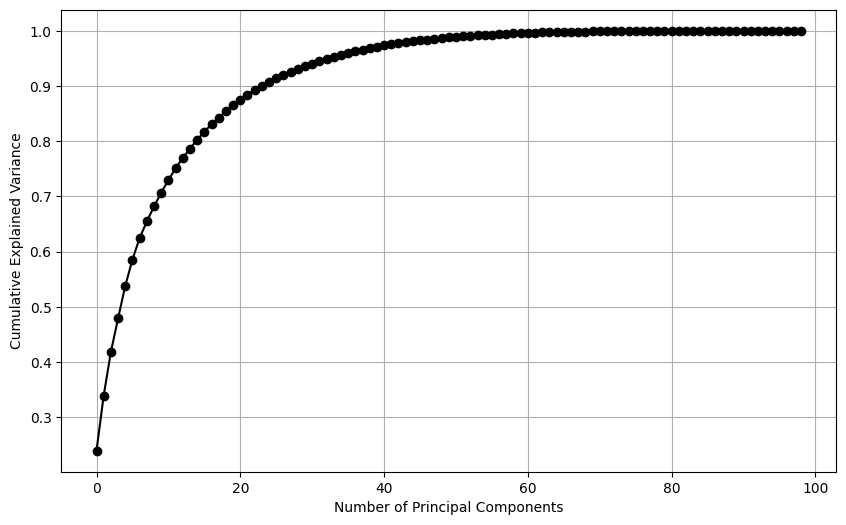

In [12]:
pca = PCA(n_components=99)

pca.fit(df_train_val[predictors])
plt.figure(figsize=(10, 6))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', color = 'black')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
#plt.title('Scree Plot')
plt.grid(True)
plt.show()


In [13]:
embeding_dim = 17
pca = PCA(n_components=embeding_dim)
reduced_train_X = pca.fit_transform(df_train_val[predictors])
reduced_test_X= pca.transform(df_test[predictors])



After this point there should be: 
- reduced train set (reduced_train_X) 
- reduced test set (reduced_test_X) to be compatible with next parts of notebook. 

Both in the form of Numpy array or pandas df but without Y(label) -- only X(predictors)

- embeding_dim should be specified which is number of column in descibet sets. 

In [14]:
reduced_df_train = pd.DataFrame(reduced_train_X, columns=[f'{i+1}' for i in range(embeding_dim)])
components = reduced_df_train.columns.to_list()
reduced_df_train['pond_5'] = df_train_val['pond_5'].reset_index(drop=True)
reduced_df_train['pond_3'] = df_train_val['pond_3'].reset_index(drop=True)
reduced_df_train['pond_2'] = df_train_val['pond_2'].reset_index(drop=True)
reduced_df_test = pd.DataFrame(reduced_test_X, columns=[f'{i+1}' for i in range(embeding_dim)])
reduced_df_test['pond_5'] = df_test['pond_5'].reset_index(drop=True)
reduced_df_test['pond_3'] = df_test['pond_3'].reset_index(drop=True)
reduced_df_test['pond_2'] = df_test['pond_2'].reset_index(drop=True)


print(components)

['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17']


# 5 classes


In [50]:
target = 'pond_5'

## dense model 
fitting on embeded dataset


In [16]:
model5 = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(0.25),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(5, activation='softmax')

])
model5.summary()
model5.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │            45 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,125 (43.46 KB)

 Trainable params: 11,125 (43.46 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 5
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.5500 - loss: 1.6801
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
predicted classes:       [3 3 4 2 2 3 0 0 3 1 3 0 4 4 0 2 4 3 4 2]
true validation classes: [3 3 1 2 2 0 1 1 3 1 1 4 2 4 0 2 4 1 3 2]
mean confidence score: 107.7426, sd confidence score: 206.9542
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5500 - loss: 2.0657
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
predicted classes:       [1 2 3 2 4 1 2 2 3 4 4 3 4 4 4 2 3 1 2 4]
true validation classes: [0 0 0 2 4 0 0 2 3 0 1 3 4 4 0 2 3 1 2 1]
mean confidence score: 1533.3631, sd confidence score: 5049.3589
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6000 - loss: 2.0978
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
predicted classes:       [1 1 3 2 0 4 4 3 1 4 1 3 4 4 2 3 3 1 4 3]
true validation classes: [1 1 2 2 0 4 0 3 0 4 3 1 4 2 2 1 3 1 4 1]
mean confidence score: 1490.885, sd confidence score

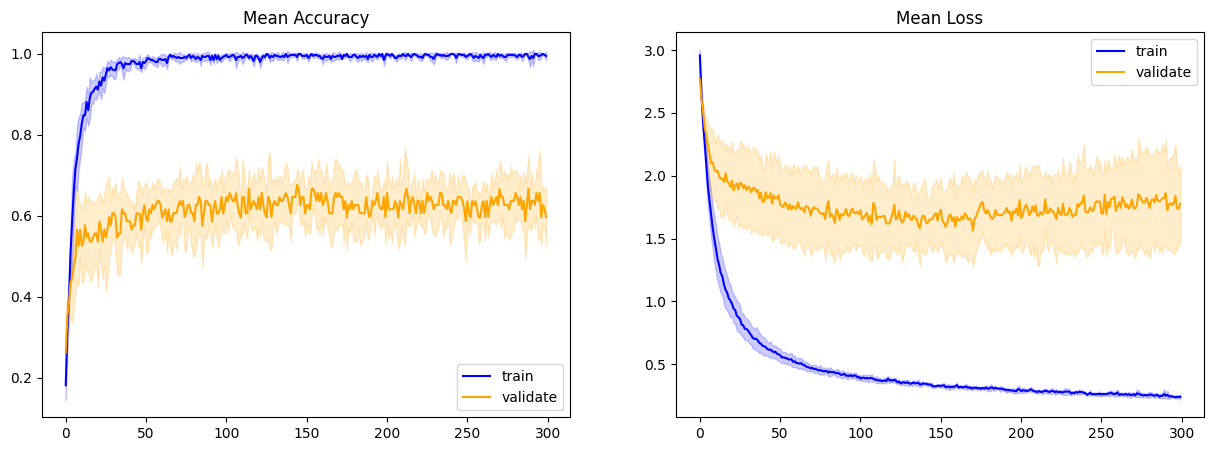

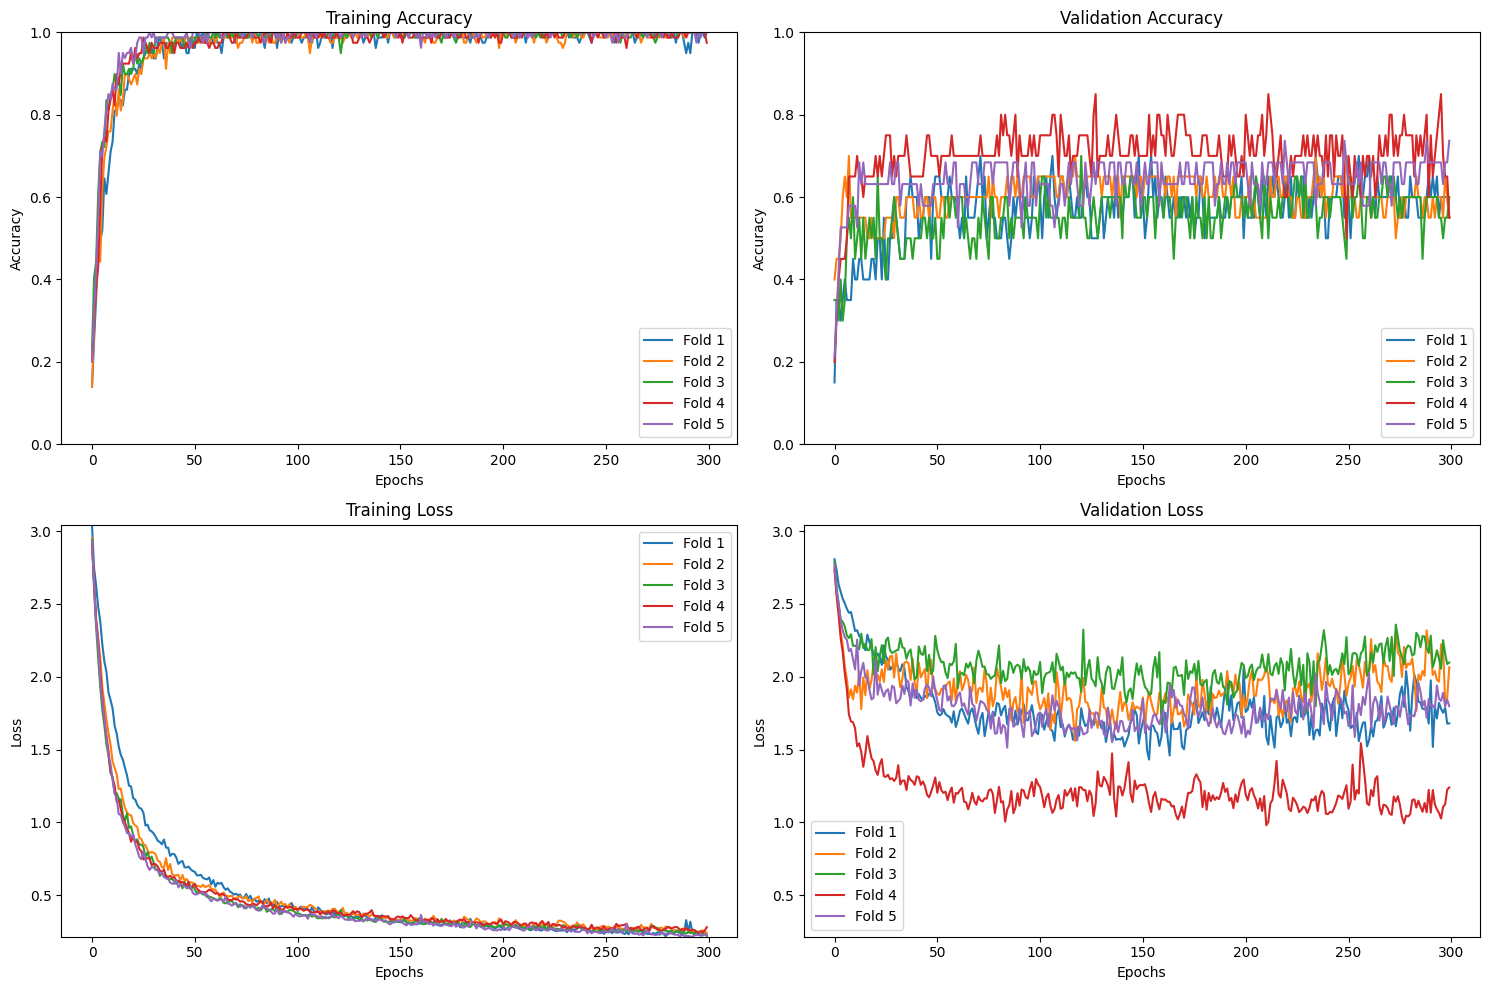

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
predicted classes:       [4 0 4 2 0 0 3 1 2 0 0 4 4 1 3 0 4 0 3]
true validation classes: [4 0 4 2 2 0 3 1 2 0 2 4 4 3 3 4 1 0 3]


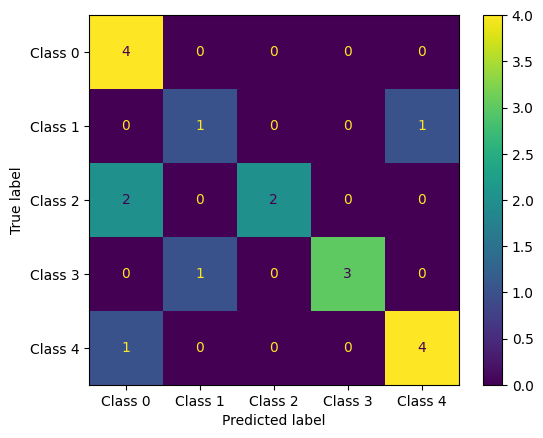

In [17]:
reset_weights(model5)
mean_acc_DNN_5_val, sd_acc_DNN_5_val = crossvalidate(reduced_df_train, model5, components, target, kf, 300)

### Test

In [51]:
X_train = reduced_df_train[components]
y_train = reduced_df_train[target]
y_train = keras.utils.to_categorical(y_train)

X_test = reduced_df_test[components]
y_test = reduced_df_test[target]
y_test = keras.utils.to_categorical(y_test)

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1784 - loss: 2.9459 - val_accuracy: 0.2800 - val_loss: 2.6888
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3087 - loss: 2.6203 - val_accuracy: 0.4000 - val_loss: 2.5344
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4745 - loss: 2.3447 - val_accuracy: 0.3200 - val_loss: 2.3781
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5407 - loss: 2.0411 - val_accuracy: 0.4000 - val_loss: 2.1804
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7705 - loss: 1.7026 - val_accuracy: 0.4800 - val_loss: 2.0486
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7131 - loss: 1.6485 - val_accuracy: 0.4800 - val_loss: 2.0524
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7386 - loss: 1.4934 - val_accuracy: 0.4000 - val_loss: 1.9963
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7305 - loss: 1.4845 - val_accuracy: 0.4800 - v

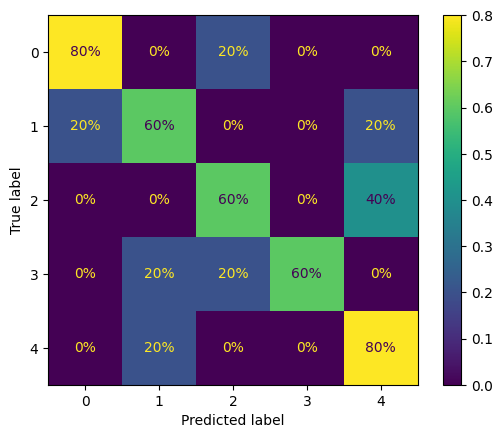

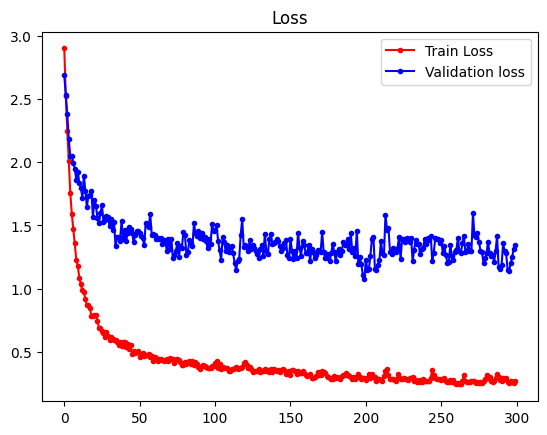

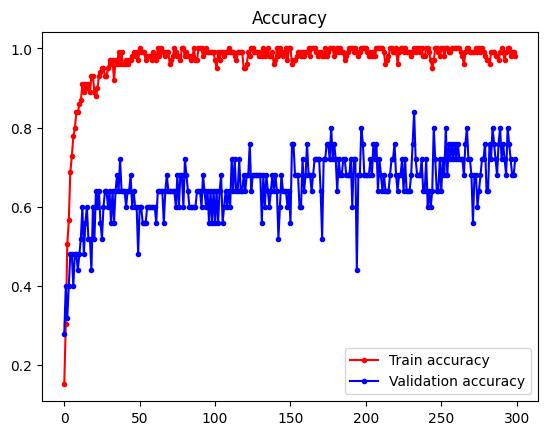

In [19]:
reset_weights(model5)
history5=model5.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, 
                    batch_size = 3, validation_data = (X_test, y_test), 
                    callbacks = [EarlyStopping(monitor='val_loss', patience=100, 
                                               restore_best_weights=True)])
acc_DNN_5_test = evaluate_model(model5, history5, X_test, y_test)

## Shallow model

In [52]:
model5_s = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(19, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(5, activation='softmax')
])
model5_s.summary()
model5_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 19)             │           342 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 5)              │           100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 442 (1.73 KB)

 Trainable params: 442 (1.73 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 5
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.6000 - loss: 1.7994
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
predicted classes:       [3 3 0 2 2 0 0 0 3 1 3 0 2 4 2 2 4 3 2 2]
true validation classes: [3 3 1 2 2 0 1 1 3 1 1 4 2 4 0 2 4 1 3 2]
mean confidence score: 295.1183, sd confidence score: 1128.7661
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5500 - loss: 1.6364
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
predicted classes:       [1 4 0 3 4 1 4 2 3 4 1 3 1 4 4 2 3 1 2 4]
true validation classes: [0 0 0 2 4 0 0 2 3 0 1 3 4 4 0 2 3 1 2 1]
mean confidence score: 476.8401, sd confidence score: 1843.049
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4500 - loss: 2.5809
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
predicted classes:       [3 1 4 2 3 4 4 3 1 4 1 3 4 0 2 3 3 1 3 3]
true validation classes: [1 1 2 2 0 4 0 3 0 4 3 1 4 2 2 1 3 1 4 1]
mean confidence score: 456.3509, sd confidence score:

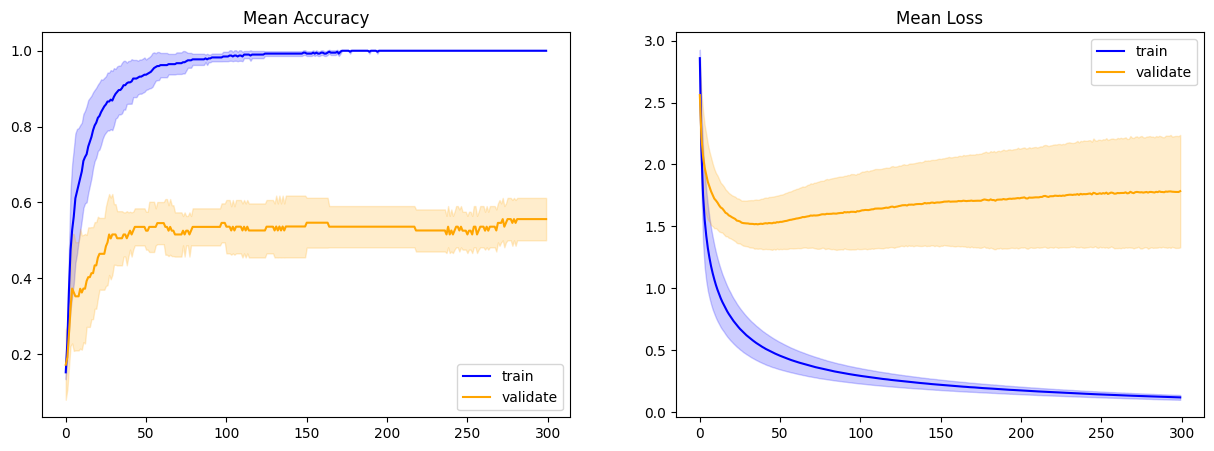

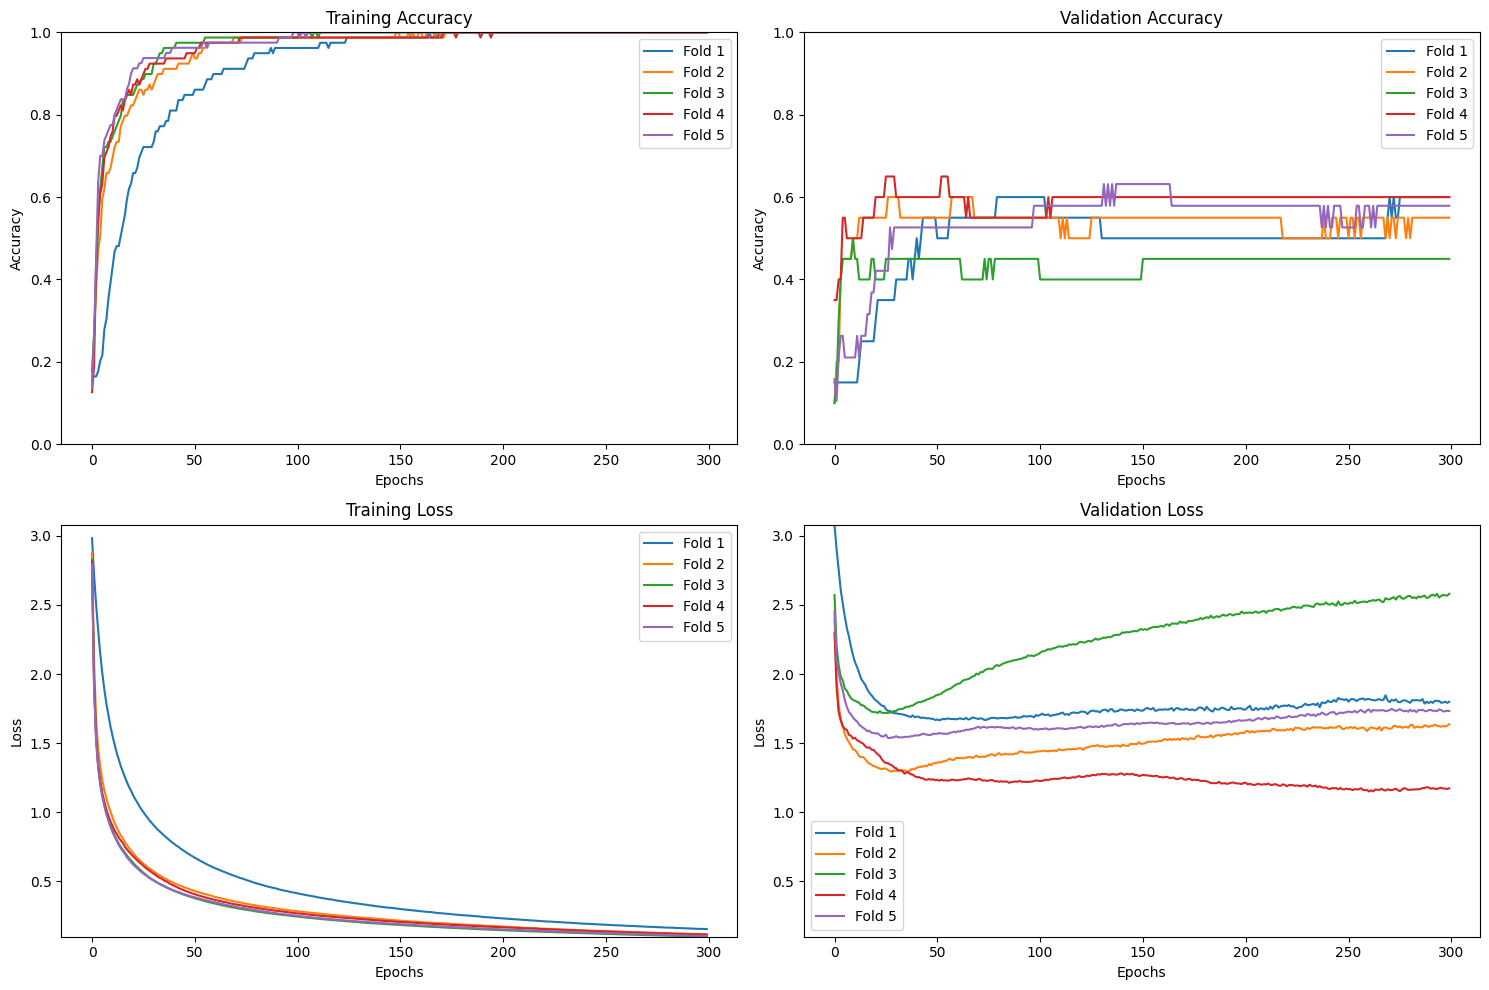

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
predicted classes:       [0 0 4 0 0 0 3 3 2 0 0 4 4 1 3 0 4 0 3]
true validation classes: [4 0 4 2 2 0 3 1 2 0 2 4 4 3 3 4 1 0 3]


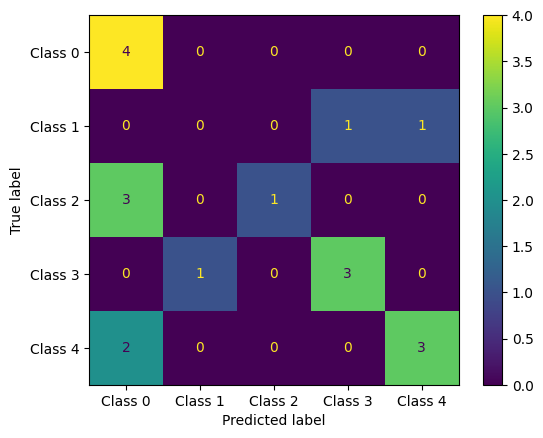

In [53]:
reset_weights(model5_s)
mean_acc_SNN_5_val, sd_acc_SNN_5_val = crossvalidate(reduced_df_train, model5_s, components, target,kf,300,True)


### Test    

In [54]:
X_train = reduced_df_train[components]
y_train = reduced_df_train[target]
y_train = keras.utils.to_categorical(y_train)

X_test = reduced_df_test[components]
y_test = reduced_df_test[target]
y_test = keras.utils.to_categorical(y_test)

In [55]:
model5_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9555 - loss: 0.2351 - val_accuracy: 0.6000 - val_loss: 0.9541
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8963 - loss: 0.5051 - val_accuracy: 0.6400 - val_loss: 1.0017
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8885 - loss: 0.4163 - val_accuracy: 0.6400 - val_loss: 1.0314
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9411 - loss: 0.2887 - val_accuracy: 0.6800 - val_loss: 1.0598
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9411 - loss: 0.2607 - val_accuracy: 0.6800 - val_loss: 1.0954
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9671 - loss: 0.2262 - val_accuracy: 0.6800 - val_loss: 1.1059
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9866 - loss: 0.1588 - val_accuracy: 0.6400 - val_loss: 1.1196
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9477 - loss: 0.2455 - val_accuracy: 0.6000 - v

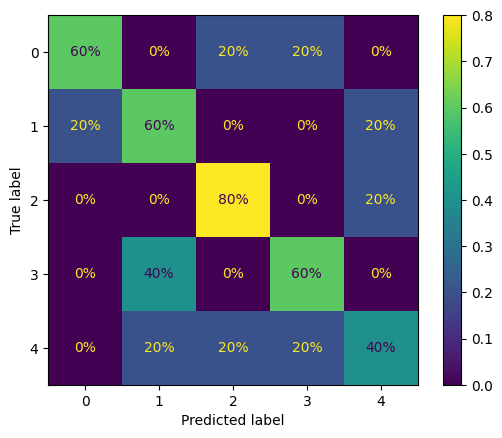

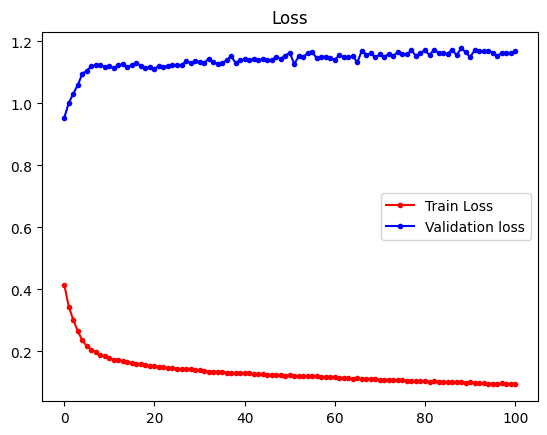

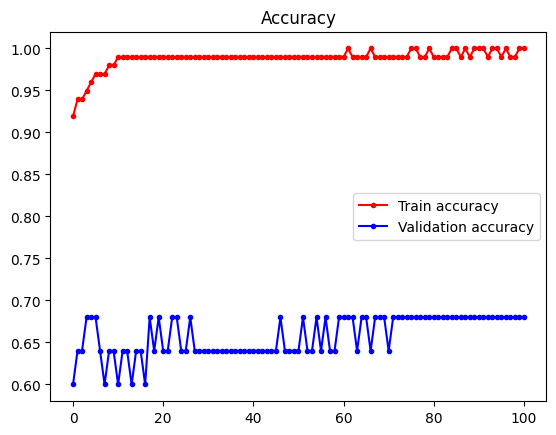

In [56]:
history5_s=model5_s.fit(X_train, y_train, epochs = 500, verbose = 1, 
                        shuffle = True, batch_size = 3, validation_data = (X_test, y_test), 
                        callbacks = [EarlyStopping(monitor='val_loss', patience=100, 
                                                   restore_best_weights=True)])
acc_SNN_5_test = evaluate_model(model5_s, history5_s, X_test, y_test)

## XGBoost

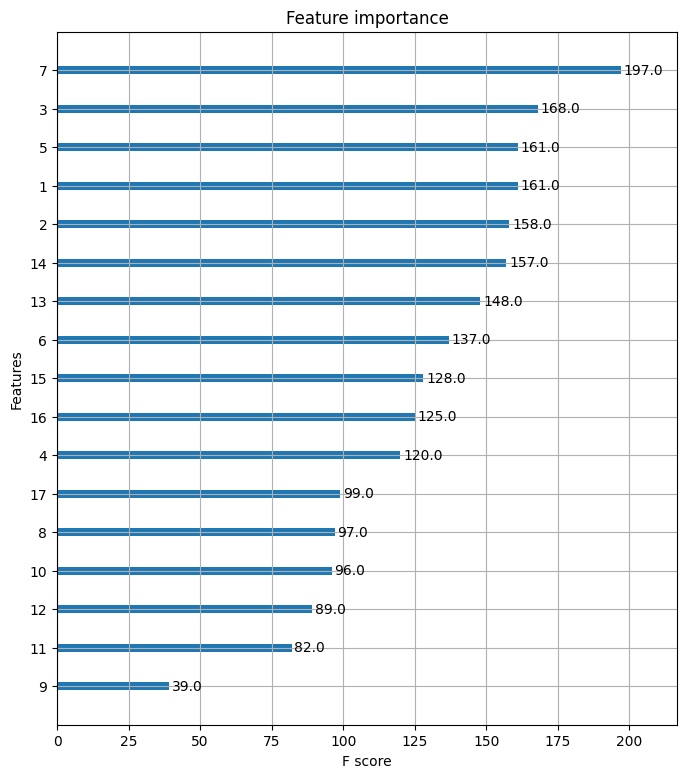

Accuracy0.56
true: [3 0 2 1 3 1 0 1 2 2 4 3 4 0 4 1 3 0 2 4 0 1 4 3 2]
predicted: [3. 2. 2. 1. 3. 4. 0. 1. 0. 4. 1. 3. 4. 0. 1. 1. 3. 4. 4. 4. 3. 1. 1. 3.
 3.]


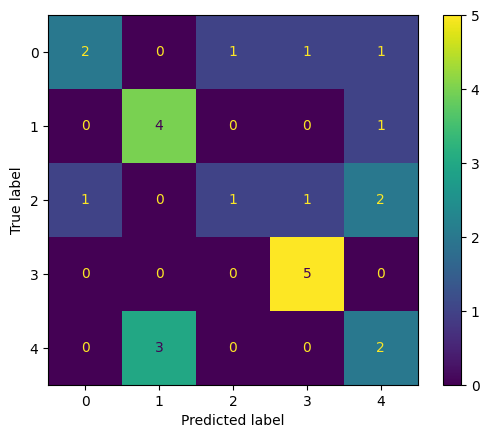

In [25]:
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=components)  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=components)
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)
acc_XGB_5_test = xgb_acc
fig, ax = plt.subplots(figsize=(8, 9))
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")

cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

# 3 Classes

In [57]:
target = 'pond_3'

## Dense model

In [27]:
model3 = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(rate=0.25),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(3, activation='softmax')
])


model3.summary()
model3.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 128)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,107 (43.39 KB)

 Trainable params: 11,107 (43.39 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 3
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.6500 - loss: 1.2536
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
predicted classes:       [1 1 2 2 2 2 0 0 1 1 1 0 2 2 2 2 2 1 2 2]
true validation classes: [1 1 1 2 2 0 1 1 1 1 1 2 2 2 0 2 2 1 1 2]
mean confidence score: 307.1978, sd confidence score: 648.7677
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5500 - loss: 1.9291
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
predicted classes:       [1 2 1 2 2 1 2 2 1 2 2 1 2 2 2 2 1 1 2 0]
true validation classes: [0 0 0 2 2 0 0 2 1 0 1 1 2 2 0 2 1 1 2 1]
mean confidence score: 2582.5048, sd confidence score: 9360.7005
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8000 - loss: 0.9197
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
predicted classes:       [1 1 1 2 2 2 2 1 1 2 1 1 2 2 2 1 1 1 2 1]
true validation classes: [1 1 2 2 0 2 0 1 0 2 1 1 2 2 2 1 1 1 2 1]
mean confidence score: 1769.9863, sd confidence scor

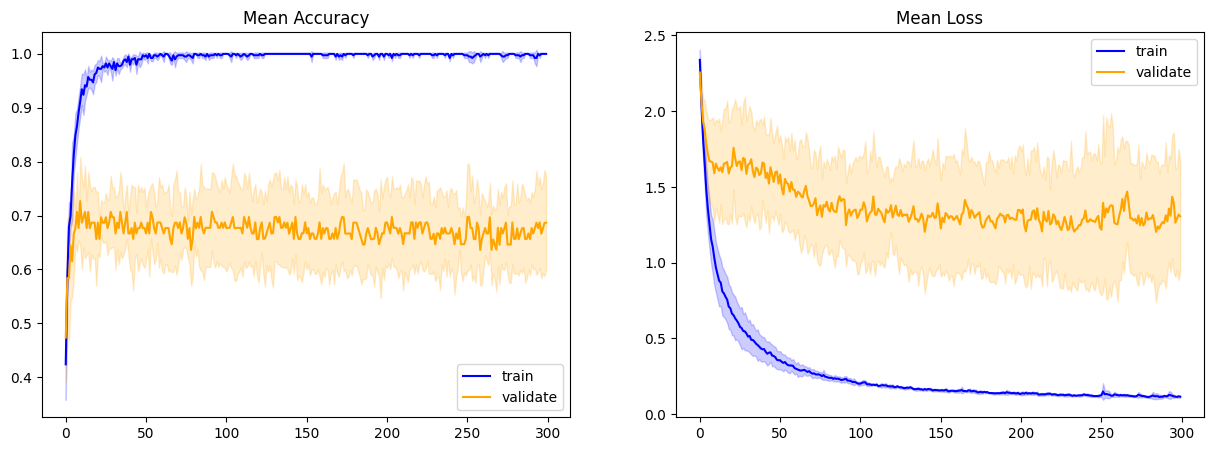

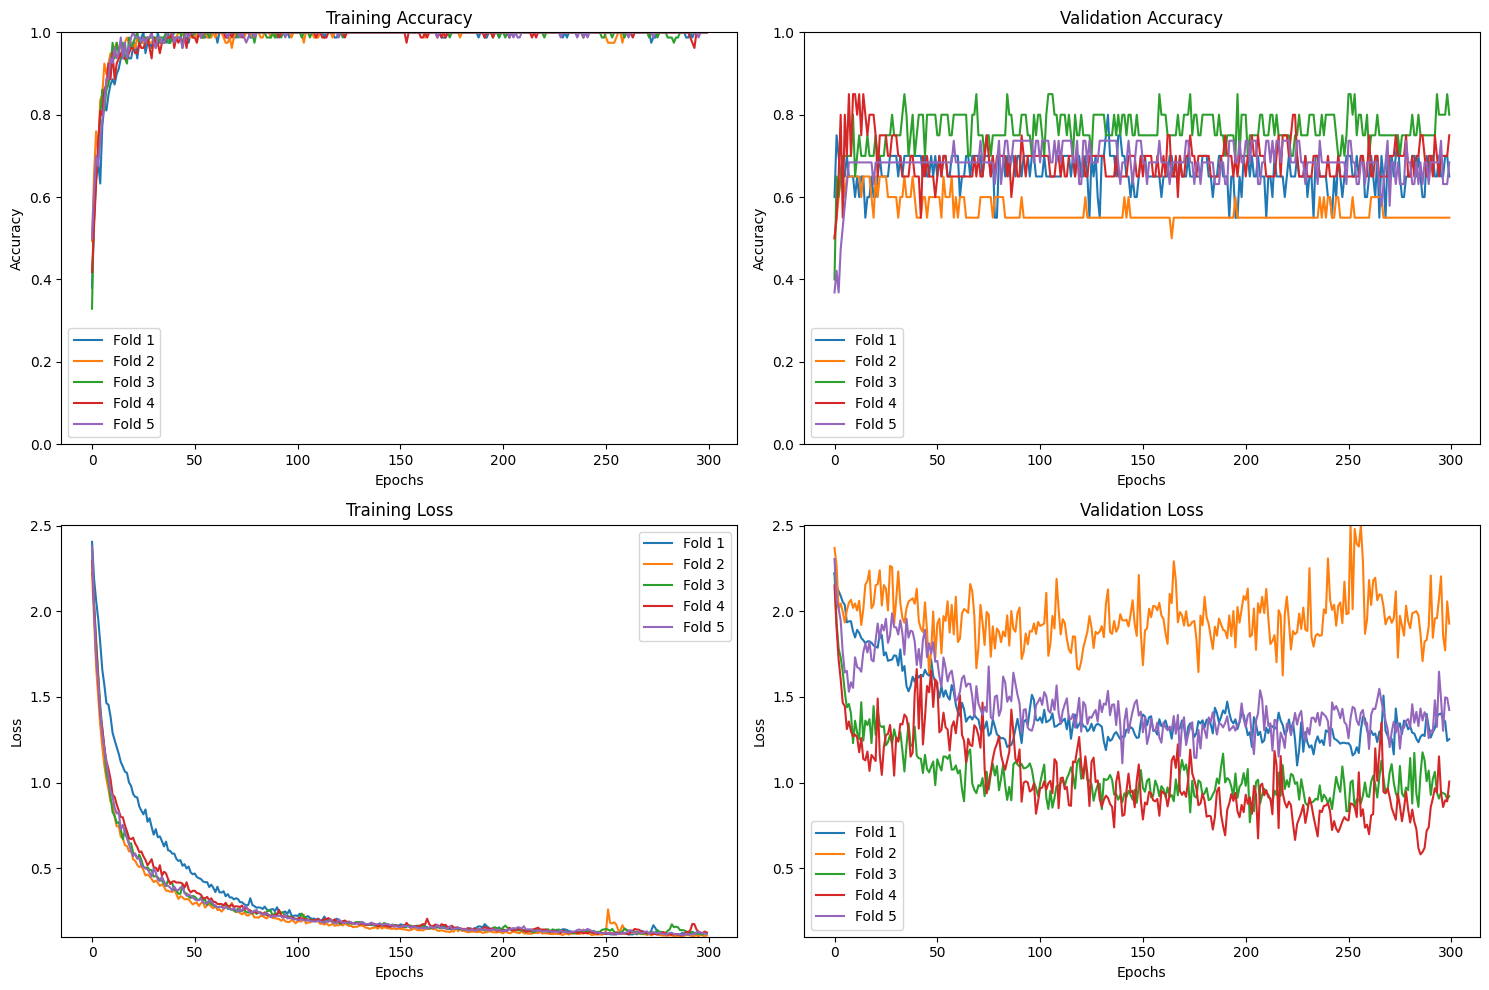

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
predicted classes:       [1 0 2 2 0 0 1 1 2 0 0 2 2 1 2 0 2 0 1]
true validation classes: [2 0 2 2 2 0 1 1 2 0 2 2 2 1 1 2 1 0 1]


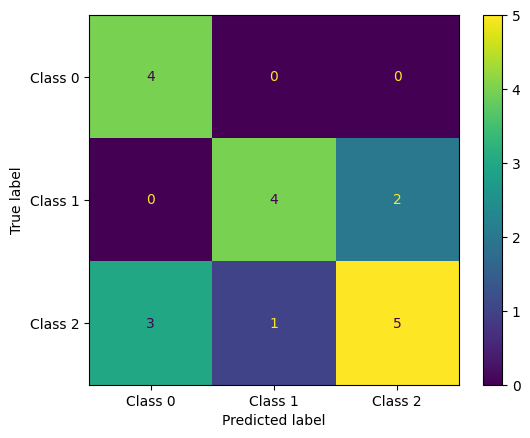

In [28]:
reset_weights(model3)
mean_acc_DNN_3_val, sd_acc_DNN_3_val = crossvalidate(reduced_df_train, model3, components, 'pond_3' ,kf,300)

### Test

In [58]:
X_train = reduced_df_train[components]
y_train = reduced_df_train[target]
y_train = keras.utils.to_categorical(y_train)

X_test = reduced_df_test[components]
y_test = reduced_df_test[target]
y_test = keras.utils.to_categorical(y_test)

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4547 - loss: 2.2876 - val_accuracy: 0.4800 - val_loss: 1.9158
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5183 - loss: 1.8826 - val_accuracy: 0.6000 - val_loss: 1.7063
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6558 - loss: 1.6079 - val_accuracy: 0.6000 - val_loss: 1.5909
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7159 - loss: 1.3419 - val_accuracy: 0.7200 - val_loss: 1.4460
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9427 - loss: 1.0342 - val_accuracy: 0.7600 - val_loss: 1.3715
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8984 - loss: 1.0326 - val_accuracy: 0.6800 - val_loss: 1.3032
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9344 - loss: 0.8860 - val_accuracy: 0.6800 - val_loss: 1.4537
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9058 - loss: 0.8550 - val_accuracy: 0.7200 - v

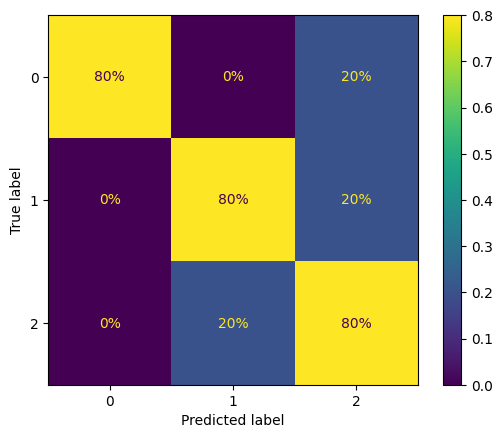

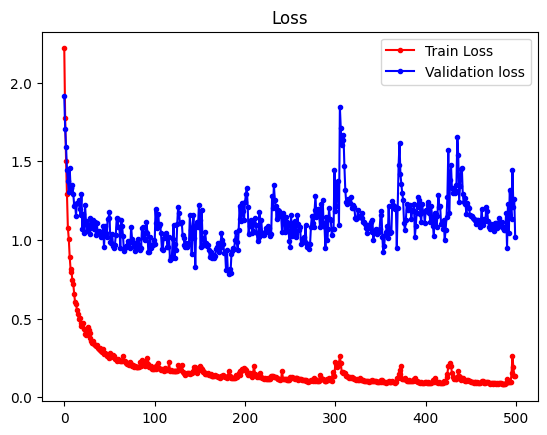

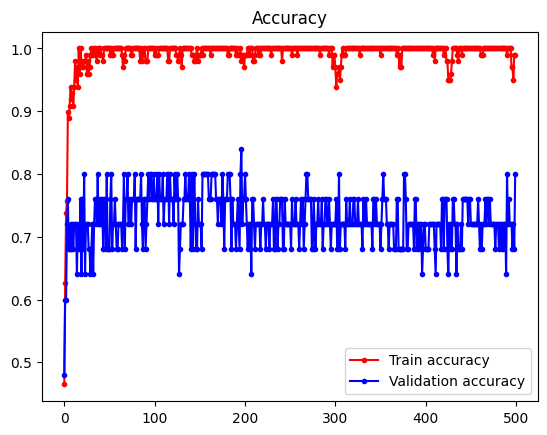

In [30]:
reset_weights(model3)
history3 = model3.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, batch_size = 3, validation_data = (X_test, y_test))
acc_DNN_3_test = evaluate_model(model3, history3, X_test, y_test)

## Shallow model 

In [61]:
model3_s = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(19, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(3, activation='softmax')
])
model3_s.summary()
model3_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_22 (Dense)                │ (None, 19)             │           342 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 3)              │            60 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 402 (1.57 KB)

 Trainable params: 402 (1.57 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 3
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.6500 - loss: 1.1244
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
predicted classes:       [1 1 2 2 2 0 0 0 1 1 1 2 2 2 1 1 1 1 2 2]
true validation classes: [1 1 1 2 2 0 1 1 1 1 1 2 2 2 0 2 2 1 1 2]
mean confidence score: 350.1894, sd confidence score: 842.637
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5500 - loss: 1.8802
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
predicted classes:       [1 2 1 2 2 1 2 2 1 0 2 2 2 2 2 2 1 1 2 0]
true validation classes: [0 0 0 2 2 0 0 2 1 0 1 1 2 2 0 2 1 1 2 1]
mean confidence score: 119208.9256, sd confidence score: 404438.3394
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7500 - loss: 0.8755
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
predicted classes:       [1 1 1 2 2 1 2 1 1 2 1 1 2 2 2 1 1 1 2 1]
true validation classes: [1 1 2 2 0 2 0 1 0 2 1 1 2 2 2 1 1 1 2 1]
mean confidence score: 912266.5334, sd confidence

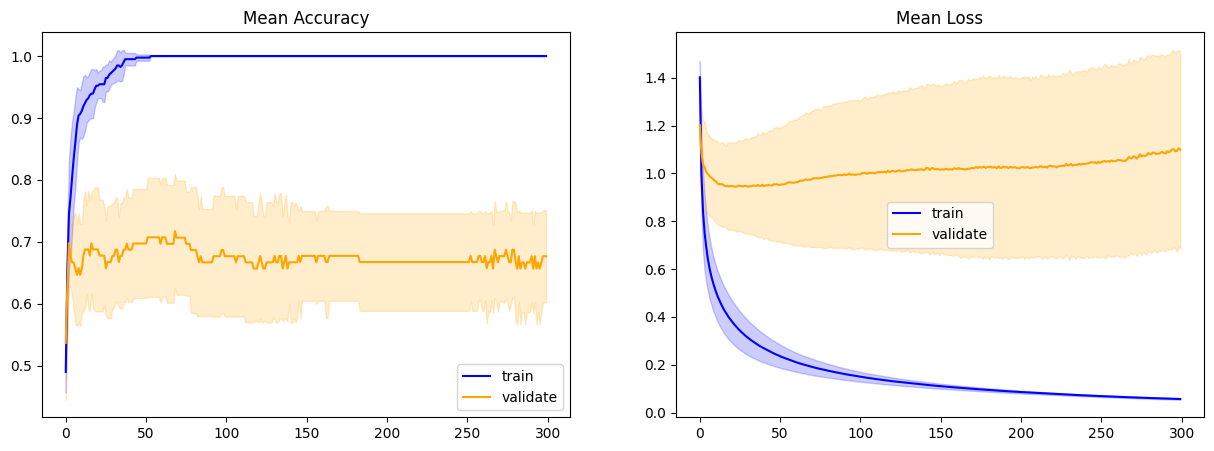

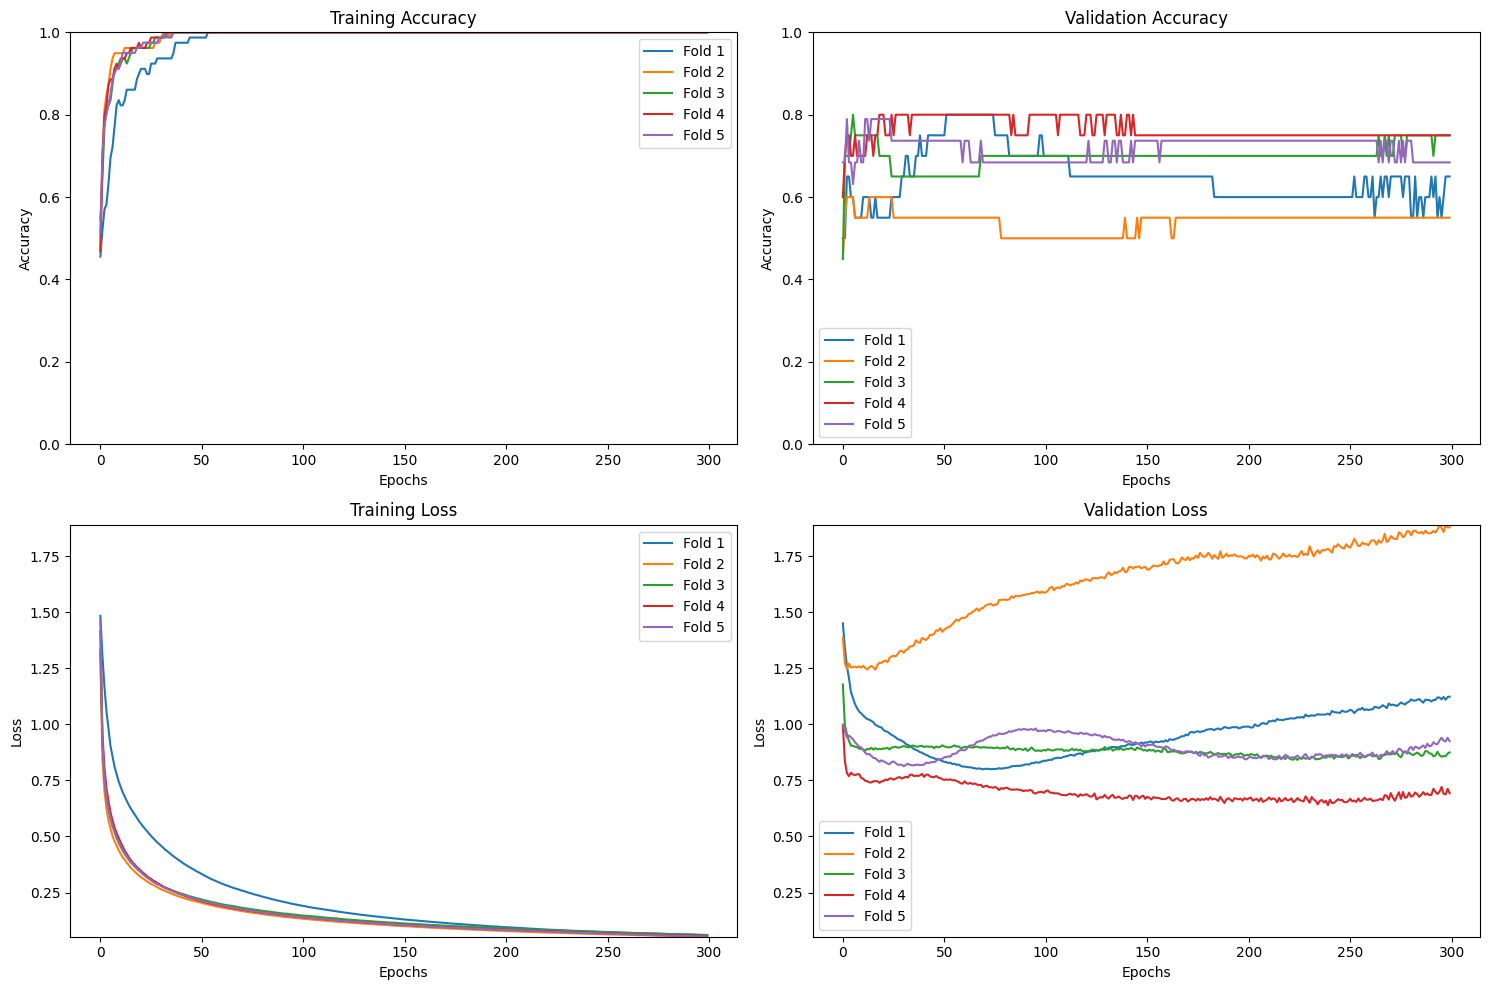

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
predicted classes:       [1 0 2 2 0 2 1 1 2 0 0 2 2 1 1 0 2 0 1]
true validation classes: [2 0 2 2 2 0 1 1 2 0 2 2 2 1 1 2 1 0 1]


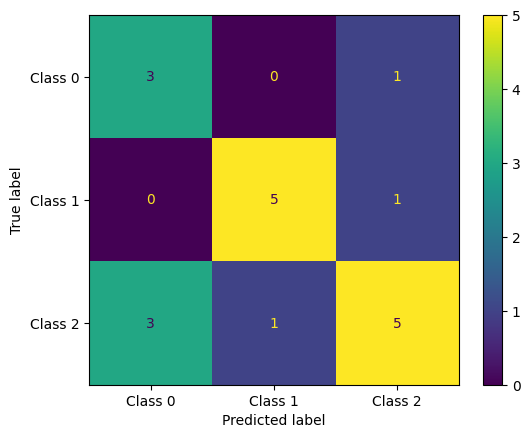

In [62]:
reset_weights(model3_s)
mean_acc_SNN_3_val, sd_acc_SNN_3_val = crossvalidate(reduced_df_train, model3_s, components, 'pond_3' ,kf,300)

### test

In [63]:
model3_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8400 - loss: 0.7564
[0.7564136981964111, 0.8399999737739563]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Predicted values: [1 2 2 1 1 2 0 1 2 2 2 2 2 0 2 1 1 0 2 2 0 1 1 1 2]
True values: [1 0 2 1 1 1 0 1 2 2 2 1 2 0 2 1 1 0 2 2 0 1 2 1 2]
Test accuracy: 0.800000011920929


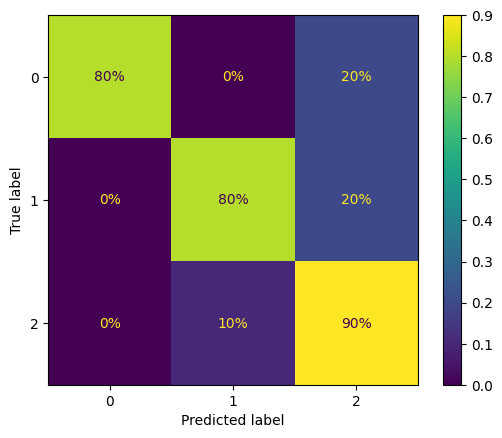

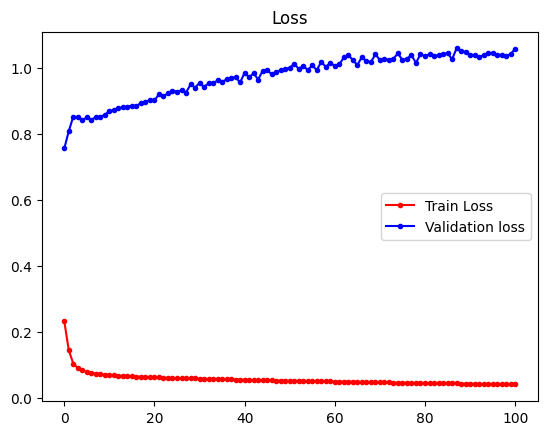

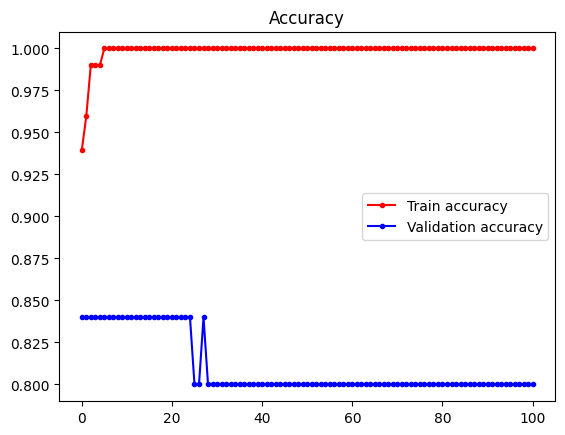

In [64]:
history3_s=model3_s.fit(X_train, y_train, epochs = 500, verbose = 0, shuffle = True, batch_size = 3, validation_data = (X_test, y_test), callbacks = [EarlyStopping(monitor='val_loss', patience=100, restore_best_weights=True)])
acc_SNN_3_test = evaluate_model(model3_s, history3_s, X_test, y_test)

## XGBoost

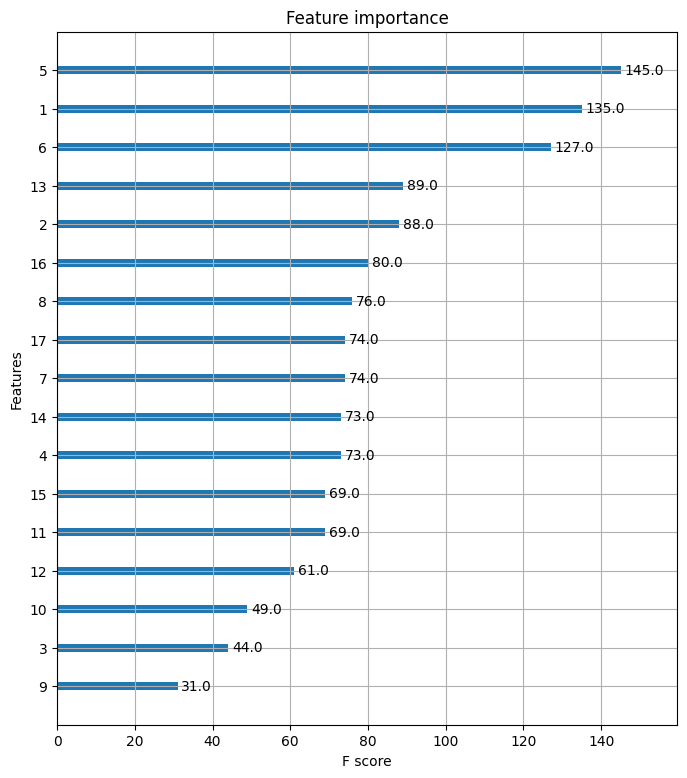

Accuracy0.64
true: [1 0 2 1 1 1 0 1 2 2 2 1 2 0 2 1 1 0 2 2 0 1 2 1 2]
predicted: [1. 2. 2. 1. 1. 2. 1. 1. 0. 2. 1. 2. 2. 0. 2. 1. 1. 1. 2. 2. 1. 1. 1. 1.
 2.]


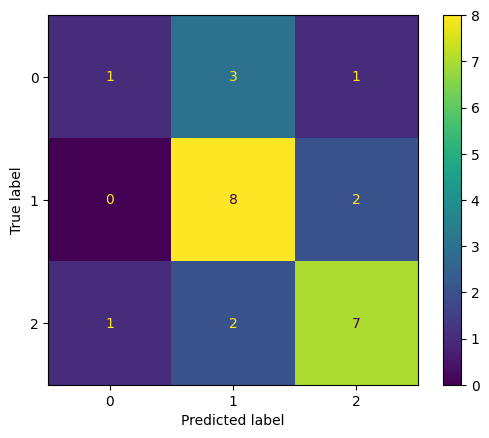

In [35]:
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=components)  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=components)
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)
acc_XGB_3_test = xgb_acc
fig, ax = plt.subplots(figsize=(8, 9))
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")

cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

# 2 Classes

In [65]:
target = 'pond_2'

## Dense model

In [66]:
X_train = reduced_df_train[components]
y_train = reduced_df_train[target]
y_train = keras.utils.to_categorical(y_train)

X_test = reduced_df_test[components]
y_test = reduced_df_test[target]
y_test = keras.utils.to_categorical(y_test)

In [38]:
model2 = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(0.25),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(2, activation='softmax')
])
model2.summary()
model2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 128)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 8)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,098 (43.35 KB)

 Trainable params: 11,098 (43.35 KB)

 Non-trainable params: 0 (0.00 B)

### Crossvalidation

Number of classes: 2
training for 1 subset


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - accuracy: 0.7000 - loss: 0.8971
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
predicted classes:       [0 0 1 1 1 1 0 0 0 0 0 0 1 1 1 0 1 0 1 1]
true validation classes: [0 0 0 1 1 0 0 0 0 0 0 1 1 1 0 1 1 0 0 1]
mean confidence score: 2021.6276, sd confidence score: 6347.3682
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8500 - loss: 0.7120
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
predicted classes:       [0 0 0 0 1 0 1 1 0 0 0 0 1 1 1 1 0 0 1 0]
true validation classes: [0 0 0 1 1 0 0 1 0 0 0 0 1 1 0 1 0 0 1 0]
mean confidence score: 520.3736, sd confidence score: 1026.0523
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8000 - loss: 0.6733
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
predicted classes:       [0 0 0 1 0 0 1 0 0 1 0 0 1 1 1 0 0 0 0 0]
true validation classes: [0 0 1 1 0 1 0 0 0 1 0 0 1 1 1 0 0 0 1 0]
mean confidence score: 512.3624, sd confidence score: 1150.4493
training for 4 subset
1/1 ━━━━

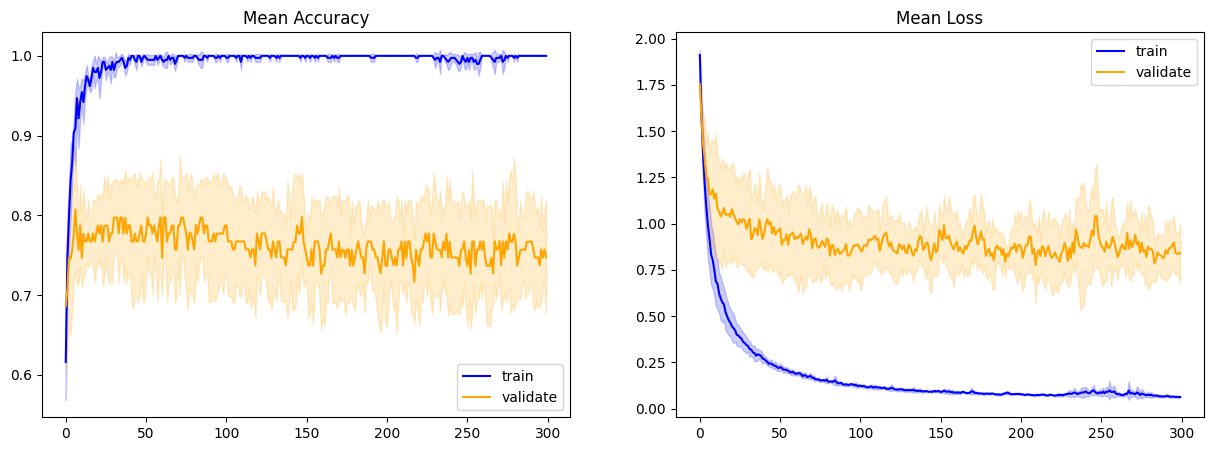

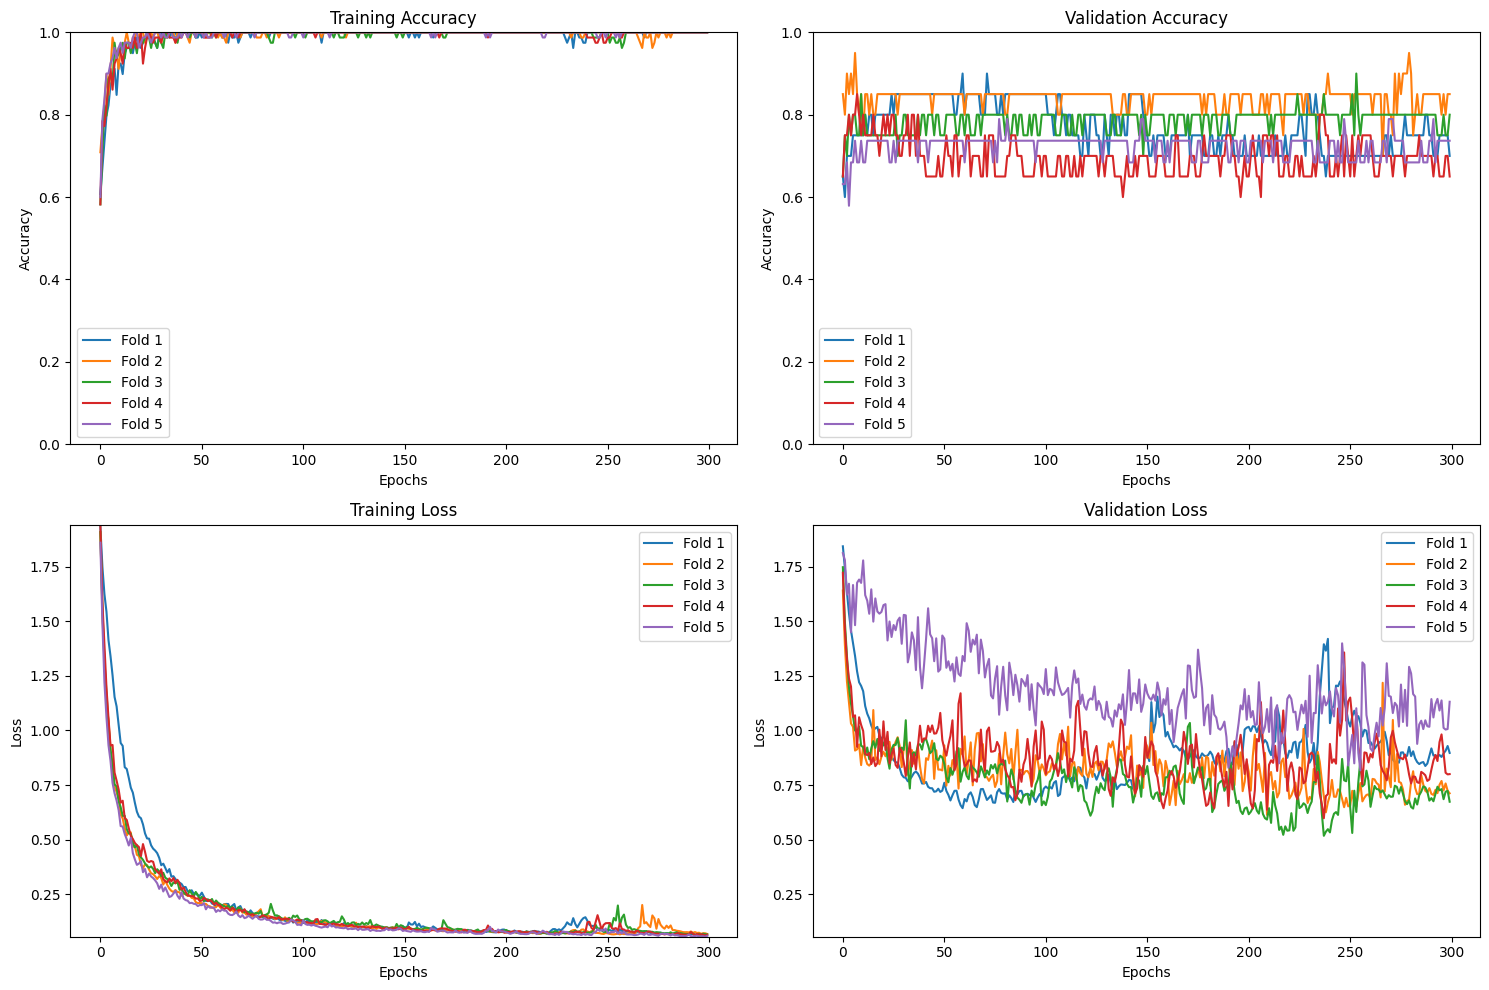

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
predicted classes:       [0 0 1 1 0 0 0 0 1 0 0 1 1 0 0 0 1 0 0]
true validation classes: [1 0 1 1 1 0 0 0 1 0 1 1 1 0 0 1 0 0 0]


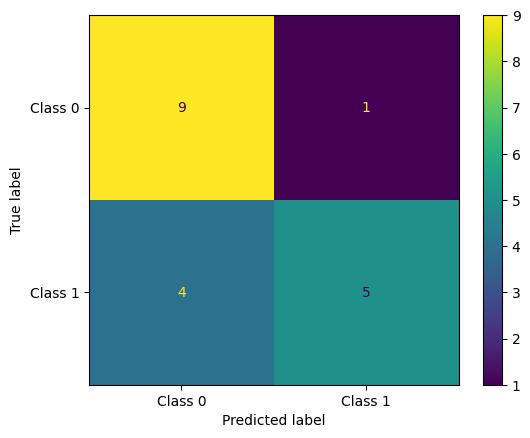

In [39]:
#reset_weights(model4)
mean_acc_DNN_2_val, sd_acc_DNN_2_val = crossvalidate(reduced_df_train, model2, components, target ,kf,300)

### Test

Epoch 1/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9503 - loss: 0.2238 - val_accuracy: 0.7200 - val_loss: 1.0614
Epoch 2/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8380 - loss: 0.4680 - val_accuracy: 0.7200 - val_loss: 0.8637
Epoch 3/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9765 - loss: 0.1982 - val_accuracy: 0.8400 - val_loss: 0.6979
Epoch 4/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9800 - loss: 0.1655 - val_accuracy: 0.6800 - val_loss: 0.9445
Epoch 5/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9521 - loss: 0.2086 - val_accuracy: 0.8000 - val_loss: 1.3073
Epoch 6/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9871 - loss: 0.1305 - val_accuracy: 0.7600 - val_loss: 1.2699
Epoch 7/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9906 - loss: 0.1183 - val_accuracy: 0.8000 - val_loss: 1.0002
Epoch 8/500
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9905 - loss: 0.1198 - val_accuracy: 0.8000 - v

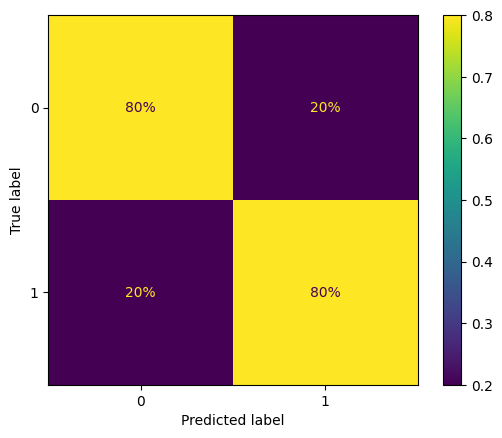

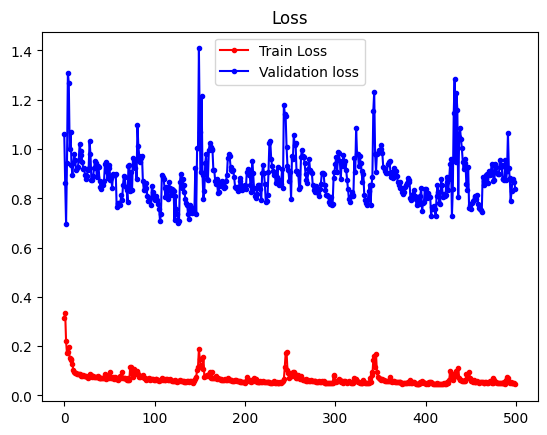

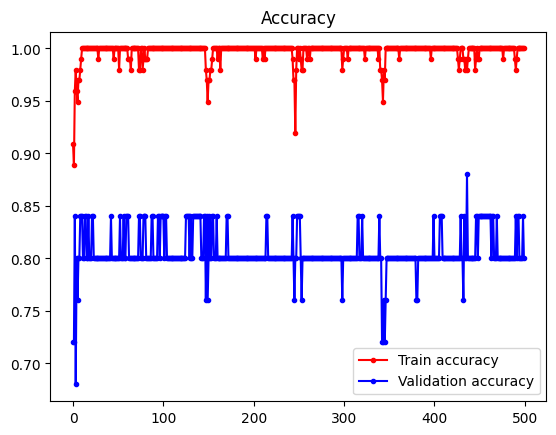

In [40]:
#  reset_weights(model4)
history2 = model2.fit(X_train, y_train, epochs = 500, verbose = 1, shuffle = True, batch_size = 3, validation_data = (X_test, y_test))
acc_DNN_2_test = evaluate_model(model2, history2, X_test, y_test)

## Shallow model

In [67]:
model2_s = Sequential([
    Input(shape=(embeding_dim,)),
    Dense(19, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(2, activation='softmax')
])
model2_s.summary()
model2_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 19)             │           342 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 2)              │            40 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 382 (1.49 KB)

 Trainable params: 382 (1.49 KB)

 Non-trainable params: 0 (0.00 B)

Number of classes: 2
training for 1 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.8500 - loss: 0.5944
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
predicted classes:       [0 0 1 1 1 0 0 0 0 0 0 0 1 1 0 1 1 0 1 1]
true validation classes: [0 0 0 1 1 0 0 0 0 0 0 1 1 1 0 1 1 0 0 1]
mean confidence score: 58038.0796, sd confidence score: 238925.2728
training for 2 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7500 - loss: 1.2531
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
predicted classes:       [0 1 1 1 1 0 1 1 0 1 0 0 1 1 1 1 0 0 1 0]
true validation classes: [0 0 0 1 1 0 0 1 0 0 0 0 1 1 0 1 0 0 1 0]
mean confidence score: 656429.8532, sd confidence score: 2807029.7698
training for 3 subset
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8000 - loss: 0.4386
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
predicted classes:       [0 0 0 1 0 0 1 0 0 1 0 0 1 1 1 0 0 0 0 0]
true validation classes: [0 0 1 1 0 1 0 0 0 1 0 0 1 1 1 0 0 0 1 0]
mean confidence score: 1952.2026, sd confi

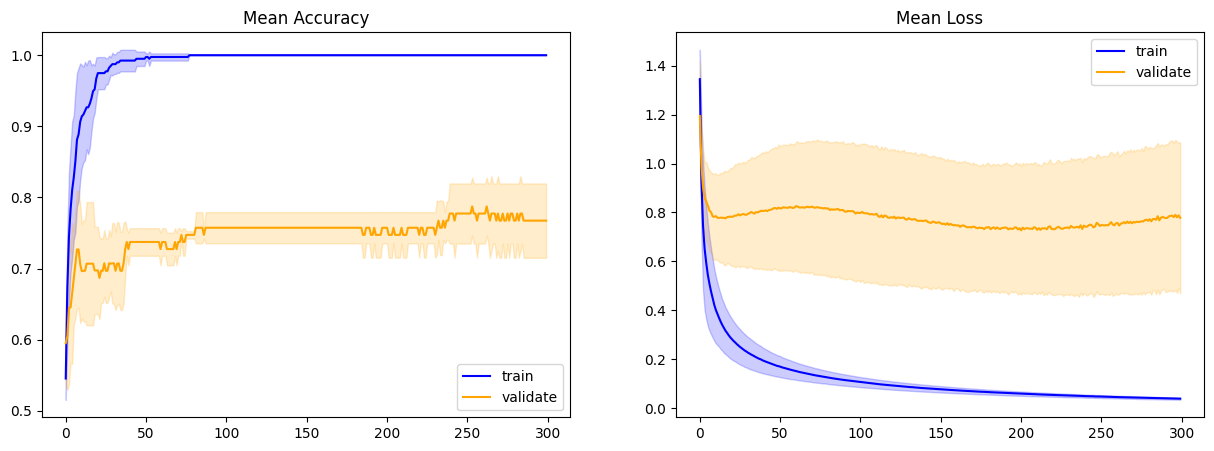

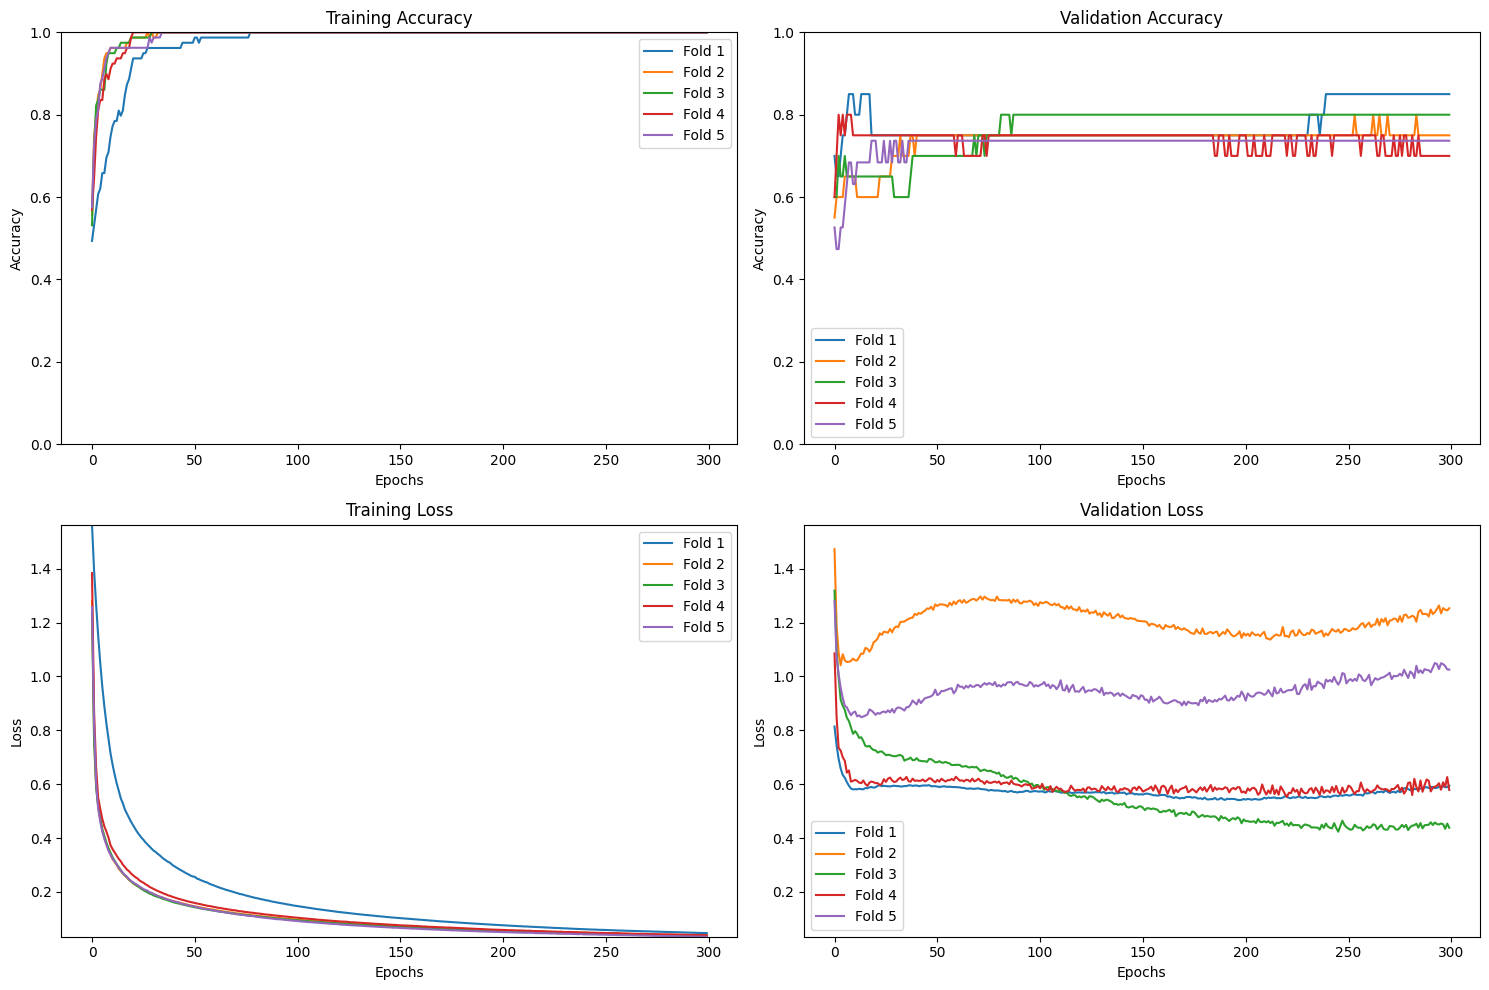

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
predicted classes:       [0 0 1 1 0 0 0 0 1 0 0 1 1 0 0 0 1 0 0]
true validation classes: [1 0 1 1 1 0 0 0 1 0 1 1 1 0 0 1 0 0 0]


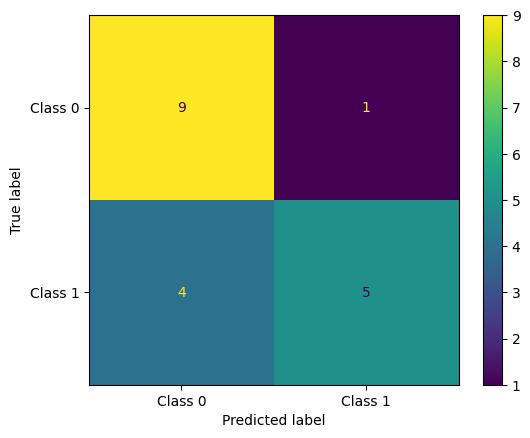

In [68]:
mean_acc_SNN_2_val, sd_acc_SNN_2_val = crossvalidate(reduced_df_train, model2_s, components, target ,kf,300,True)

### test

In [69]:
model2_s.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])   

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.8000 - loss: 0.5743
[0.5743388533592224, 0.800000011920929]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Predicted values: [0 1 1 0 0 1 0 0 0 1 1 0 1 0 1 0 0 0 0 1 0 0 0 0 1]
True values: [0 0 1 0 0 0 0 0 1 1 1 0 1 0 1 0 0 0 1 1 0 0 1 0 1]
Test accuracy: 0.7599999904632568


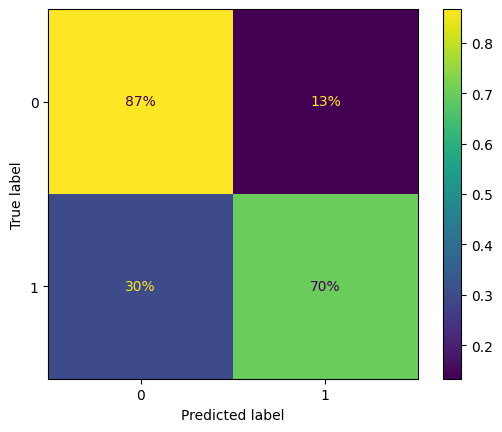

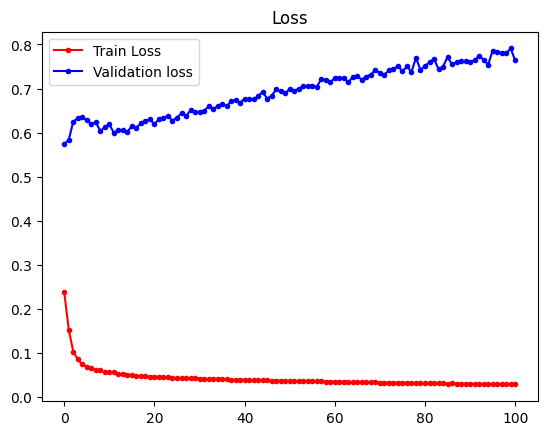

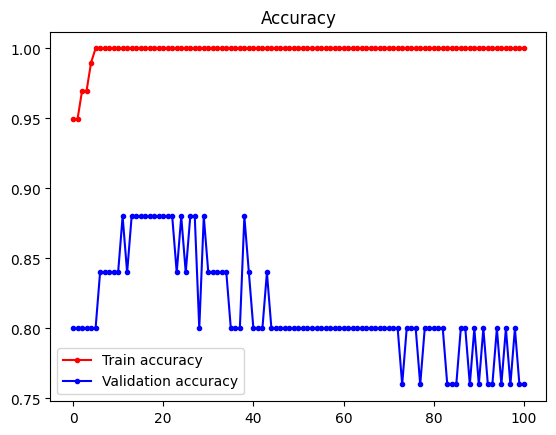

In [70]:
history2_s=model2_s.fit(X_train, y_train, epochs = 500, verbose = 0, shuffle = True, batch_size = 3, validation_data = (X_test, y_test), callbacks = [EarlyStopping(monitor='val_loss', patience=100, restore_best_weights=True)])
acc_SNN_2_test = evaluate_model(model2_s, history2_s, X_test, y_test)

## XGboost

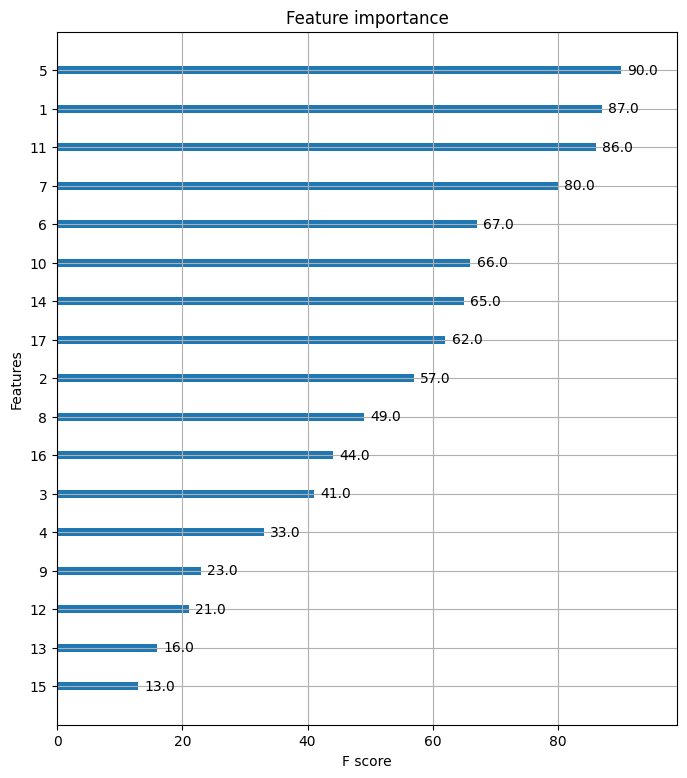

Accuracy0.72
true: [0 0 1 0 0 0 0 0 1 1 1 0 1 0 1 0 0 0 1 1 0 0 1 0 1]
predicted: [0. 1. 1. 0. 0. 0. 0. 0. 0. 1. 0. 1. 1. 0. 1. 0. 0. 0. 0. 1. 0. 1. 0. 0.
 1.]


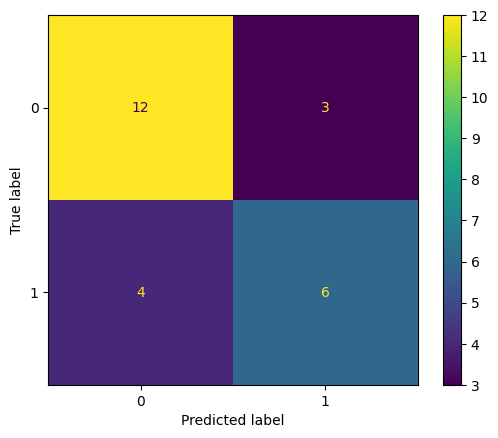

In [45]:
dtrain = xgb.DMatrix(X_train, label=df_train_val[target].values, feature_names=components)  
dtest = xgb.DMatrix(X_test, label=df_test[target].values, feature_names=components)
params = {
    'objective': 'multi:softmax',
    'num_class': 5,
    'max_depth': 3, 
    'eta': 0.1,
    'seed': 111
}

x2 = xgb.train(params, dtrain, num_boost_round=100)

xgb_pred = x2.predict(dtest)
xgb_acc = accuracy_score(df_test[target].values, xgb_pred)
acc_XGB_2_test = xgb_acc
fig, ax = plt.subplots(figsize=(8, 9))
xgb.plot_importance(x2, ax=ax)
plt.show()

print(f"Accuracy{xgb_acc}")
print(f"true: {df_test[target].values}")
print(f"predicted: {xgb_pred}")

cm = confusion_matrix(df_test[target].values, xgb_pred)
ConfusionMatrixDisplay(cm).plot()

# END

In [71]:
print("DNN")
print(f"Accuracy class 5: {round(mean_acc_DNN_5_val,2)}, sd: {round(sd_acc_DNN_5_val,2)}, test: {acc_DNN_5_test}")
print(f"Accuracy class 3: {round(mean_acc_DNN_3_val,2)}, sd: {round(sd_acc_DNN_3_val,2)}, test: {acc_DNN_3_test}")
print(f"Accuracy class 2: {round(mean_acc_DNN_2_val,2)}, sd: {round(sd_acc_DNN_2_val,2)}, test: {acc_DNN_2_test}")
print("SNN")
print(f"Accuracy class 5: {round(mean_acc_SNN_5_val,2)}, sd: {round(sd_acc_SNN_5_val,2)}, test: {acc_SNN_5_test}")
print(f"Accuracy class 3: {round(mean_acc_SNN_3_val,2)}, sd: {round(sd_acc_SNN_3_val,2)}, test: {acc_SNN_3_test}")
print(f"Accuracy class 2: {round(mean_acc_SNN_2_val,2)}, sd: {round(sd_acc_SNN_2_val,2)}, test: {acc_SNN_2_test}")
print("XGB")
print(f"Accuracy class 5: {acc_XGB_5_test}")
print(f"Accuracy class 3: {acc_XGB_3_test}")
print(f"Accuracy class 2: {acc_XGB_2_test}")


DNN
Accuracy class 5: 0.6, sd: 0.07, test: 0.7200000286102295
Accuracy class 3: 0.69, sd: 0.09, test: 0.800000011920929
Accuracy class 2: 0.75, sd: 0.07, test: 0.800000011920929
SNN
Accuracy class 5: 0.56, sd: 0.06, test: 0.6800000071525574
Accuracy class 3: 0.68, sd: 0.07, test: 0.800000011920929
Accuracy class 2: 0.77, sd: 0.05, test: 0.7599999904632568
XGB
Accuracy class 5: 0.56
Accuracy class 3: 0.64
Accuracy class 2: 0.72


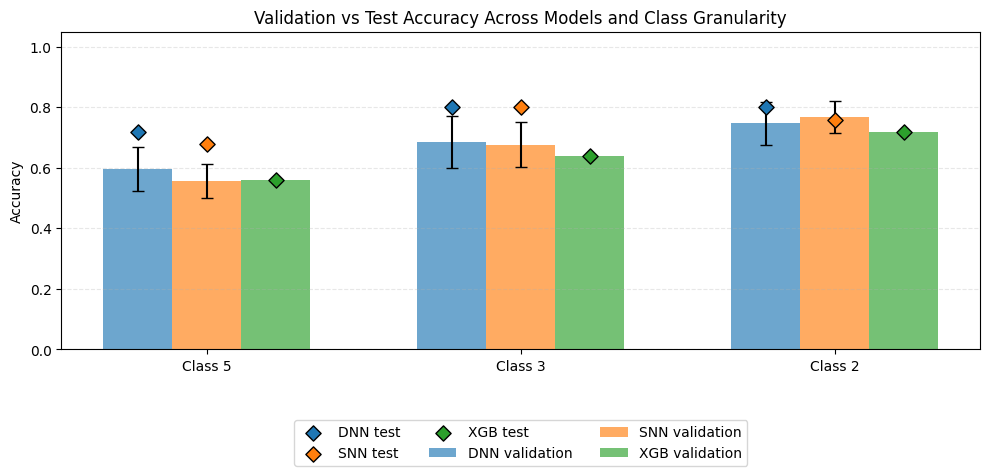

In [72]:
accuracy_rows = [
    ("DNN", "Class 5", mean_acc_DNN_5_val, sd_acc_DNN_5_val, acc_DNN_5_test),
    ("DNN", "Class 3", mean_acc_DNN_3_val, sd_acc_DNN_3_val, acc_DNN_3_test),
    ("DNN", "Class 2", mean_acc_DNN_2_val, sd_acc_DNN_2_val, acc_DNN_2_test),
    ("SNN", "Class 5", mean_acc_SNN_5_val, sd_acc_SNN_5_val, acc_SNN_5_test),
    ("SNN", "Class 3", mean_acc_SNN_3_val, sd_acc_SNN_3_val, acc_SNN_3_test),
    ("SNN", "Class 2", mean_acc_SNN_2_val, sd_acc_SNN_2_val, acc_SNN_2_test),
    ("XGB", "Class 5", acc_XGB_5_test, 0.0, acc_XGB_5_test),
    ("XGB", "Class 3", acc_XGB_3_test, 0.0, acc_XGB_3_test),
    ("XGB", "Class 2", acc_XGB_2_test, 0.0, acc_XGB_2_test),
]

accuracy_df = pd.DataFrame(
    accuracy_rows,
    columns=["Model", "Class", "val_mean", "val_sd", "test_acc"],
)

class_labels = ["Class 5", "Class 3", "Class 2"]
model_order = ["DNN", "SNN", "XGB"]
x_positions = np.arange(len(class_labels))
bar_width = 0.22
palette = {"DNN": "#1f77b4", "SNN": "#ff7f0e", "XGB": "#2ca02c"}

fig, ax = plt.subplots(figsize=(10, 5))
for idx, model in enumerate(model_order):
    subset = accuracy_df[accuracy_df["Model"] == model].set_index("Class").loc[class_labels]
    offsets = x_positions + (idx - (len(model_order) - 1) / 2) * bar_width
    ax.bar(
        offsets,
        subset["val_mean"],
        bar_width,
        yerr=subset["val_sd"],
        capsize=4,
        alpha=0.65,
        color=palette[model],
        label=f"{model} validation",
    )
    ax.scatter(
        offsets,
        subset["test_acc"],
        color=palette[model],
        edgecolors="black",
        marker="D",
        s=60,
        zorder=3,
        label=f"{model} test",
    )

ax.set_xticks(x_positions)
ax.set_xticklabels(class_labels)
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("Validation vs Test Accuracy Across Models and Class Granularity")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(ncol=3, bbox_to_anchor=(0.5, -0.2), loc="upper center")
plt.tight_layout()
plt.show()

In [73]:
resultsdf = pd.DataFrame(accuracy_rows, columns=["Model", "Class", "val_mean", "val_sd", "test_acc"])
print(resultsdf)
resultsdf.to_csv("results\\Gut_4_PCA_results.csv", index=False)


  Model    Class  val_mean    val_sd  test_acc
0   DNN  Class 5  0.597368  0.072376      0.72
1   DNN  Class 3  0.686842  0.085888      0.80
2   DNN  Class 2  0.747368  0.070906      0.80
3   SNN  Class 5  0.555789  0.055983      0.68
4   SNN  Class 3  0.676842  0.074253      0.80
5   SNN  Class 2  0.767368  0.052278      0.76
6   XGB  Class 5  0.560000  0.000000      0.56
7   XGB  Class 3  0.640000  0.000000      0.64
8   XGB  Class 2  0.720000  0.000000      0.72
